In [1]:
import numpy as np 
import matplotlib.pyplot as plt 

In [2]:
## Activation functions 

def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [7]:
class NeuralNetwork:
    def __init__(self, input_size, hidden_size, output_size):
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0/input_size)
        self.b1 = np.zeros((1, hidden_size))

        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0/input_size)
        self.b2 = np.zeros((1, output_size))


    def forward(self, x):
        self.x = x 
        self.Z1 = np.dot(x, self.W1) + self.b1
        self.A1 = relu(self.Z1)

        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = relu(self.Z2)

        return self.A2 

    def backward(self, Y, lr):
        m = Y.shape[0]
        dZ2 = self.A2 - Y
        dW2 = np.dot(self.A1.T, dZ2) / m 
        db2 = np.sum(dZ2, axis = 0, keepdims = True) / m 

        dA1 = np.dot(dZ2, self.W2.T)
        dZ1 = dA1 * relu_derivative(self.Z1)

        dW1 = np.dot(self.x.T, dZ1) / m 
        db1 = np.sum(dZ1, axis = 0, keepdims=True) / m 

        self.W1 -= lr * dW1 
        self.b1 -= lr * db1 
        self.W2 -= lr * dW2 
        self.b2 -= lr * db2 

    def train(self, x, Y, epochs, lr):
        for epoch in range(epochs):
            # Forward pass
            predictions = self.forward(x)
            
            # Compute Binary Cross-Entropy Loss (with epsilon for numerical stability)
            epsilon = 1e-15
            predictions = np.clip(predictions, epsilon, 1 - epsilon)
            loss = -np.mean(Y * np.log(predictions) + (1 - Y) * np.log(1 - predictions))
            
            # Backward pass & update weights
            self.backward(Y, lr)
            
            if epoch % (epochs // 5 == 0 and epochs // 5 or 1) == 0:
                print(f"Epoch {epoch}/{epochs} - Loss: {loss:.4f}")


In [8]:
# XOR Dataset
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
Y_xor = np.array([[0], [1], [1], [0]])

# Initialize and train MLP
np.random.seed(42)
xor_net = NeuralNetwork(input_size=2, hidden_size=4, output_size=1)
print("--- Training on XOR Problem ---")
xor_net.train(X_xor, Y_xor, epochs=5000, lr=0.5)

# Test predictions
preds = xor_net.forward(X_xor)
print("\nXOR Predictions:")
for i in range(len(X_xor)):
    print(f"Input: {X_xor[i]} | True: {Y_xor[i][0]} | Predicted: {preds[i][0]:.4f}")

--- Training on XOR Problem ---
Epoch 0/5000 - Loss: 17.2694
Epoch 1/5000 - Loss: 17.3413
Epoch 2/5000 - Loss: 0.7670
Epoch 3/5000 - Loss: 0.7479
Epoch 4/5000 - Loss: 0.7343
Epoch 5/5000 - Loss: 0.7257
Epoch 6/5000 - Loss: 0.7188
Epoch 7/5000 - Loss: 0.7138
Epoch 8/5000 - Loss: 0.7097
Epoch 9/5000 - Loss: 0.7063
Epoch 10/5000 - Loss: 0.7034
Epoch 11/5000 - Loss: 0.7009
Epoch 12/5000 - Loss: 0.6986
Epoch 13/5000 - Loss: 0.6965
Epoch 14/5000 - Loss: 0.6946
Epoch 15/5000 - Loss: 0.6927
Epoch 16/5000 - Loss: 0.6909
Epoch 17/5000 - Loss: 0.6891
Epoch 18/5000 - Loss: 0.6873
Epoch 19/5000 - Loss: 0.6855
Epoch 20/5000 - Loss: 0.6836
Epoch 21/5000 - Loss: 0.6817
Epoch 22/5000 - Loss: 0.6796
Epoch 23/5000 - Loss: 0.6774
Epoch 24/5000 - Loss: 0.6751
Epoch 25/5000 - Loss: 0.6736
Epoch 26/5000 - Loss: 0.6722
Epoch 27/5000 - Loss: 0.6695
Epoch 28/5000 - Loss: 0.6688
Epoch 29/5000 - Loss: 0.6654
Epoch 30/5000 - Loss: 0.6639
Epoch 31/5000 - Loss: 0.6612
Epoch 32/5000 - Loss: 0.6584
Epoch 33/5000 - Los

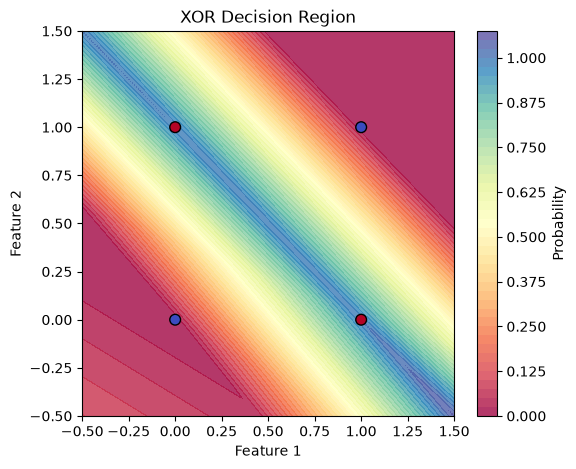

In [9]:
def plot_decision_boundary(model, X, Y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    
    grid = np.c_[xx.ravel(), yy.ravel()]
    preds = model.forward(grid)
    preds = preds.reshape(xx.shape)
    
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, preds, levels=50, cmap=plt.cm.Spectral, alpha=0.8)
    plt.colorbar(label='Probability')
    plt.scatter(X[:, 0], X[:, 1], c=Y.ravel(), cmap=plt.cm.coolwarm, edgecolor='k', s=60)
    plt.title(title)
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.show()

plot_decision_boundary(xor_net, X_xor, Y_xor, "XOR Decision Region")

In [11]:
## Two moon dataset 


from sklearn.datasets import make_moons

# Generate Two Moons data
X_moon, Y_moon = make_moons(n_samples=300, noise=0.2, random_state=42)
Y_moon = Y_moon.reshape(-1, 1) # Reshape to column vector

# Initialize and train MLP
np.random.seed(42)
moon_net = NeuralNetwork(input_size=2, hidden_size=8, output_size=1)
print("\n--- Training on Two Moons Problem ---")
moon_net.train(X_moon, Y_moon, epochs=4000, lr=0.1)


--- Training on Two Moons Problem ---
Epoch 0/4000 - Loss: 15.7926
Epoch 1/4000 - Loss: 15.7723
Epoch 2/4000 - Loss: 15.4361
Epoch 3/4000 - Loss: 14.3700
Epoch 4/4000 - Loss: 13.4364
Epoch 5/4000 - Loss: 11.5151
Epoch 6/4000 - Loss: 9.4973
Epoch 7/4000 - Loss: 0.9492
Epoch 8/4000 - Loss: 0.5931
Epoch 9/4000 - Loss: 0.5620
Epoch 10/4000 - Loss: 0.5448
Epoch 11/4000 - Loss: 0.5330
Epoch 12/4000 - Loss: 0.5235
Epoch 13/4000 - Loss: 0.5161
Epoch 14/4000 - Loss: 0.5102
Epoch 15/4000 - Loss: 0.5052
Epoch 16/4000 - Loss: 0.5009
Epoch 17/4000 - Loss: 0.4973
Epoch 18/4000 - Loss: 0.4942
Epoch 19/4000 - Loss: 0.4915
Epoch 20/4000 - Loss: 0.4892
Epoch 21/4000 - Loss: 0.4871
Epoch 22/4000 - Loss: 0.4853
Epoch 23/4000 - Loss: 0.3892
Epoch 24/4000 - Loss: 0.3854
Epoch 25/4000 - Loss: 0.3828
Epoch 26/4000 - Loss: 0.3809
Epoch 27/4000 - Loss: 0.3792
Epoch 28/4000 - Loss: 0.3778
Epoch 29/4000 - Loss: 0.3765
Epoch 30/4000 - Loss: 0.3755
Epoch 31/4000 - Loss: 0.3746
Epoch 32/4000 - Loss: 0.3738
Epoch 33

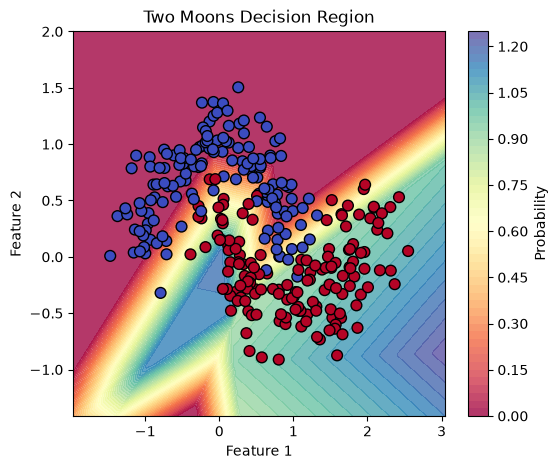

In [12]:
plot_decision_boundary(moon_net, X_moon, Y_moon, "Two Moons Decision Region")